# 05.8 · Solutions

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/05-powerful-models/08-explaining-models/solutions.ipynb)

## Exercise 1

Order A→B: A gets 20 − 20 = **0**, B gets 60 − 20 = 40.
Order B→A: B gets 50 − 20 = 30, A gets 60 − 50 = **10**.

A = (0 + 10) / 2 = **5**, B = (40 + 30) / 2 = **35**. Check: 20 + 5 + 35 = 60.

A on its own adds nothing, but adds 10 when B is already known: an **interaction**. Shapley values split interaction credit fairly between the features involved.

## Exercise 2

Shuffled days = [90, 100, 120, 10, 20, 30] → rule predicts [1, 1, 1, 0, 0, 0] against truth [0, 0, 0, 1, 1, 1]. Accuracy **0**, importance 1 − 0 = **1.0**. A single shuffle can be lucky or unlucky; that is why real permutation importance repeats it many times and averages.

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

import sys
sys.path.insert(0, str(data_path("download.py").parent))
from download import load_retail
from sklearn.model_selection import train_test_split

raw = load_retail("Year 2010-2011")
sales = raw[~raw["Invoice"].astype(str).str.startswith("C")]
sales = sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
sales = sales.assign(Revenue=sales["Quantity"] * sales["Price"])

cutoff = pd.Timestamp("2011-09-01")                       # features before, target after
past = sales[sales["InvoiceDate"] < cutoff]
future = sales[(sales["InvoiceDate"] >= cutoff) & (sales["InvoiceDate"] < "2011-12-01")]

cust = past.groupby("Customer ID").agg(orders=("Invoice", "nunique"), spend=("Revenue", "sum"),
                                       products=("StockCode", "nunique"),
                                       first_order=("InvoiceDate", "min"), last_order=("InvoiceDate", "max"))
cust["tenure_days"] = (cutoff - cust["first_order"]).dt.days
cust["days_since_last"] = (cutoff - cust["last_order"]).dt.days
future_spend = future.groupby("Customer ID")["Revenue"].sum().reindex(cust.index).fillna(0)
cust["churned"] = (future_spend == 0).astype(int)        # 1 = did not come back
cust = cust.drop(columns=["first_order", "last_order"])

features = ["orders", "spend", "products", "tenure_days", "days_since_last"]
X_train, X_test, y_train, y_test = train_test_split(
    cust[features], cust["churned"], test_size=0.25, random_state=42, stratify=cust["churned"])
print(f"{len(cust):,} customers, churn rate {cust['churned'].mean():.1%}, "
      f"train {len(X_train):,} / test {len(X_test):,}")

import lightgbm as lgb
from sklearn.metrics import roc_auc_score
# the tuned settings found by grid search in 05.6
model = lgb.LGBMClassifier(n_estimators=200, learning_rate=0.01, num_leaves=4,
                           verbose=-1, random_state=42, n_jobs=1).fit(X_train, y_train)
print(f"tuned LightGBM, test AUC {roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]):.3f}")

six = pd.DataFrame({"orders": [5, 2, 8, 1, 3, 1], "days_since_last": [10, 20, 30, 90, 100, 120],
                    "churned": [0, 0, 0, 1, 1, 1]})
rule = lambda df: (df["days_since_last"] > 60).astype(int)     # the "model"
acc = lambda df: (rule(df) == df["churned"]).mean()

from itertools import permutations
from math import factorial

def shapley(value, players):
    """Average each player's marginal contribution over every joining order."""
    credit = {p: 0.0 for p in players}
    for order in permutations(players):
        joined = frozenset()
        for p in order:
            credit[p] += value[joined | {p}] - value[joined]
            joined = joined | {p}
    return {p: c / factorial(len(players)) for p, c in credit.items()}

3,317 customers, churn rate 43.6%, train 2,487 / test 830
tuned LightGBM, test AUC 0.739


In [2]:
print(shapley({frozenset(): 20, frozenset("A"): 20, frozenset("B"): 50, frozenset("AB"): 60}, ["A", "B"]))
print("ex 2 accuracy:", acc(six.assign(days_since_last=six["days_since_last"].values[[3, 4, 5, 0, 1, 2]])))

{'A': 5.0, 'B': 35.0}
ex 2 accuracy: 0.0


## Exercise 3

In [3]:
from sklearn.inspection import permutation_importance
out = {}
for metric in ["accuracy", "roc_auc"]:
    r = permutation_importance(model, X_test, y_test, scoring=metric, n_repeats=10, random_state=42)
    out[metric] = r.importances_mean
pd.DataFrame(out, index=features).sort_values("roc_auc", ascending=False).round(3)

,accuracy,roc_auc
orders,0.034,0.054
spend,0.023,0.026
days_since_last,0.007,0.018
products,0.013,0.011
tenure_days,-0.001,0.000


The top features are the same, but the sizes differ and small features can swap places. Accuracy only notices changes that flip predictions across 0.5; AUC notices any change in ranking. Always report importance *for the metric you care about*.

## Exercise 4

customer: 12683.0  P(churn) = 0.12
orders               11.00
spend              6217.88
products            151.00
tenure_days         265.00
days_since_last       5.00
Name: 12683.0, dtype: float64


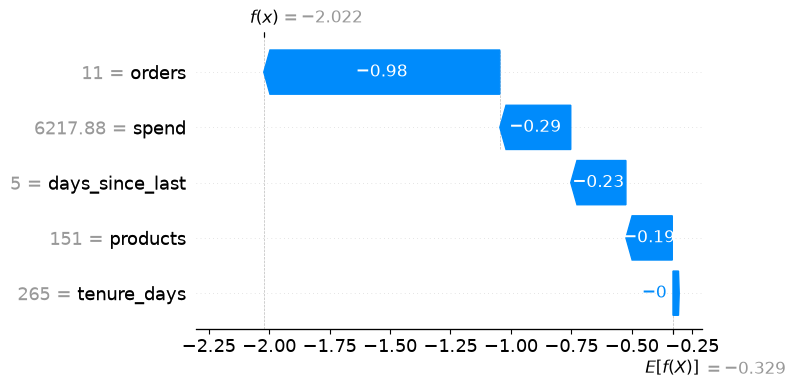

In [4]:
import shap
sv = shap.TreeExplainer(model)(X_test)
proba = model.predict_proba(X_test)[:, 1]
j = int(proba.argmin())
print("customer:", X_test.index[j], f" P(churn) = {proba[j]:.2f}")
print(X_test.iloc[j])
shap.plots.waterfall(sv[j], show=False); plt.tight_layout(); plt.show()

Typical explanation: *"This customer has ordered many times, recently, across many products. Each of those pulls the churn risk well below average; there is no reason to spend a voucher here."* Your exact numbers come from the output above.